# Latar Belakang

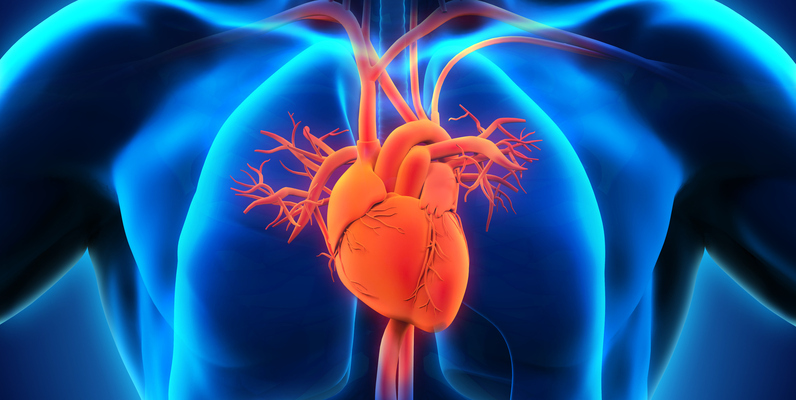

Dataset Heart Attack diunduh dari [Kaggle](https://www.kaggle.com/datasets/fatemehmohammadinia/heart-attack-dataset-tarik-a-rashid) dimana datasets ini dikumpulkan dari Zheen Hospital di Erbil, Iraq, antara Januari hingga Mei 2019, dan bertujuan untuk mengklasifikasikan apakah seorang pasien mengalami serangan jantung atau tidak berdasarkan sejumlah parameter medis. Dataset ini terdiri dari sembilan atribut, termasuk usia, jenis kelamin, denyut jantung, tekanan darah sistolik dan diastolik, kadar gula darah, serta dua biomarker jantung yaitu CK-MB dan troponin.

Nilai pada kolom gender telah dinormalisasi dengan laki-laki diberi nilai 1 dan perempuan 0, sementara kadar gula darah dinyatakan dalam bentuk biner, dengan nilai 1 jika kadar glukosa lebih dari 120 mg/dL, dan 0 jika sebaliknya. Kolom output atau hasil diagnosis juga berbentuk biner, dengan nilai 1 menunjukkan adanya serangan jantung (positif) dan 0 menunjukkan tidak ada serangan jantung (negatif). Dataset ini dapat dimanfaatkan untuk pengembangan model klasifikasi dalam mendeteksi serangan jantung secara dini berdasarkan indikator-indikator medis pasien.


# Import library


Pada awal tahapan selalu dimulai dengan mengimport library yang dibutuhkan dalam pengolahan data.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

# Data Understanding

## Data Loading

In [3]:
data = pd.read_csv('/content/Medicaldataset.csv')
data

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result
0,64,1,66,160,83,160.0,1.80,0.012,negative
1,21,1,94,98,46,296.0,6.75,1.060,positive
2,55,1,64,160,77,270.0,1.99,0.003,negative
3,64,1,70,120,55,270.0,13.87,0.122,positive
4,55,1,64,112,65,300.0,1.08,0.003,negative
...,...,...,...,...,...,...,...,...,...
1314,44,1,94,122,67,204.0,1.63,0.006,negative
1315,66,1,84,125,55,149.0,1.33,0.172,positive
1316,45,1,85,168,104,96.0,1.24,4.250,positive
1317,54,1,58,117,68,443.0,5.80,0.359,positive


Melakukan loading/ menampilkan data yang akan digunakan, dimana datasets yang dipakai bernama Medicaldataset.csv, berdasarkan output tersebut dapat diketahui informasi yang terkandung dalam datasets yaitu:


*   Ada 1.319 baris (records atau jumlah pengamatan) dalam dataset.
*   Terdapat 9 kolom yaitu: Age, Gender, Heart rate, Systolic blood pressure, Diastolic Blood Pressure, Blood Sugar, Ck-mb, Troponin, dan Result.



## Exploratory Data Analysis

### Deskripsi Variabel

Berdasarkan informasi dari [Kaggle](https://www.kaggle.com/datasets/fatemehmohammadinia/heart-attack-dataset-tarik-a-rashid), variabel-variabel pada Heart Attack Dataset adalah sebagai berikut:

* **Age**: Usia pasien
* **Gender**: Jenis kelamin biologis pasien (laki-laki diberi nilai 1 dan perempuan 0)
* **Heart Rate**: Jumlah detak jantung per menit
* **Systolic Blood Pressure**: Tekanan pada arteri saat jantung berkontraksi
* **Diastolic Blood Pressure**: Tekanan pada arteri di antara detak jantung
* **Blood Sugar**: Tingkat glukosa darah pasien
* **CK-MB**: Enzim jantung yang dilepaskan saat terjadi kerusakan otot jantung
* **Troponin**: Penanda protein yang sangat spesifik untuk cedera otot jantung
* **Result**: Label hasil yang menunjukkan apakah pasien mengalami serangan jantung atau tidak


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1319 non-null   int64  
 1   Gender                    1319 non-null   int64  
 2   Heart rate                1319 non-null   int64  
 3   Systolic blood pressure   1319 non-null   int64  
 4   Diastolic blood pressure  1319 non-null   int64  
 5   Blood sugar               1319 non-null   float64
 6   CK-MB                     1319 non-null   float64
 7   Troponin                  1319 non-null   float64
 8   Result                    1319 non-null   object 
dtypes: float64(3), int64(5), object(1)
memory usage: 92.9+ KB


Dari output diatas terlihat bahwa:


*   Terdapat 1 kolom bertipe object yaitu kolom Result Kolom ini merupakan categorical features (fitur non-numerik), kolom ini merupakan kolom target saat model development.
*   Terdapat 5 kolom bertipe integer yaitu kolom Age, Gender, Heart Rate, Systolic Blood Pressure & Diastolic Blood Pressure merupakan fitur numerik.
* Terdapat 3 kolom bertipe float yaitu kolom Blood Sugar, Ck-mb dan Troponin merupakan fitur numerik.

Dari pengamatan & perbandingan yang dilakukan pada sample datasets bahwa  setiap kolom telah memiliki tipe data yang sesuai.



## Kondisi Data

In [5]:
data.describe()

,Age,Gender,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin
count,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000
mean,56.191812,0.659591,78.336619,127.170584,72.269143,146.634344,15.274306,0.360942
std,13.647315,0.474027,51.630270,26.122720,14.033924,74.923045,46.327083,1.154568
min,14.000000,0.000000,20.000000,42.000000,38.000000,35.000000,0.321000,0.001000
25%,47.000000,0.000000,64.000000,110.000000,62.000000,98.000000,1.655000,0.006000
50%,58.000000,1.000000,74.000000,124.000000,72.000000,116.000000,2.850000,0.014000
75%,65.000000,1.000000,85.000000,143.000000,81.000000,169.500000,5.805000,0.085500
max,103.000000,1.000000,1111.000000,223.000000,154.000000,541.000000,300.000000,10.300000


Berdasarkan otuput diatas didapatkan informasi bahwa:


* Usia pasien berkisar antara 14 hingga 103 tahun, dengan usia rata-rata sekitar 56 tahun.
* Sebanyak 50% pasien berusia 58 tahun ke bawah, menunjukkan mayoritas pasien berusia setengah baya ke atas.
* Nilai maksimum 1111 bpm sangat tidak wajar dan kemungkinan merupakan outlier atau kesalahan data.
* Systolic Blood Pressure rata-rata sekitar 127 mmHg, dengan rentang 42–223 mmHg & Diastolic Blood Pressure rata-rata sekitar 72 mmHg, dengan rentang 38–154 mmHg.
* Rata-rata kadar glukosa darah adalah 146.6 mg/dL, yang berarti sebagian besar pasien memiliki kadar gula darah tinggi (lebih dari ambang normal 120 mg/dL).
* Nilai maksimum mencapai 541 mg/dL yang sangat tinggi dan menunjukkan potensi kondisi kesehatan yang sangat buruk.
* Rata-rata nilai CK-MB adalah 15.27, dengan maksimum 300, menunjukkan bahwa beberapa pasien mengalami kerusakan otot jantung yang signifikan.
* Rata-rata nilai troponin adalah 0.36, dengan maksimum 10.3. Troponin biasanya sangat rendah pada individu sehat sehingga nilai tinggi mencerminkan adanya cedera jantung yang serius.





### Data Cleaning



#### Data kosong/ Missing value

In [6]:
data.isnull().sum()

,0
Age,0
Gender,0
Heart rate,0
Systolic blood pressure,0
Diastolic blood pressure,0
Blood sugar,0
CK-MB,0
Troponin,0
Result,0


Tidak terdapat yang hilang/ kosong pada output yang ditampilkan.

#### Data duplikat

In [7]:
data.duplicated().sum()

np.int64(0)

Tidak terdapat data duplikat yang ditemukan pada output diatas.

#### Outliers

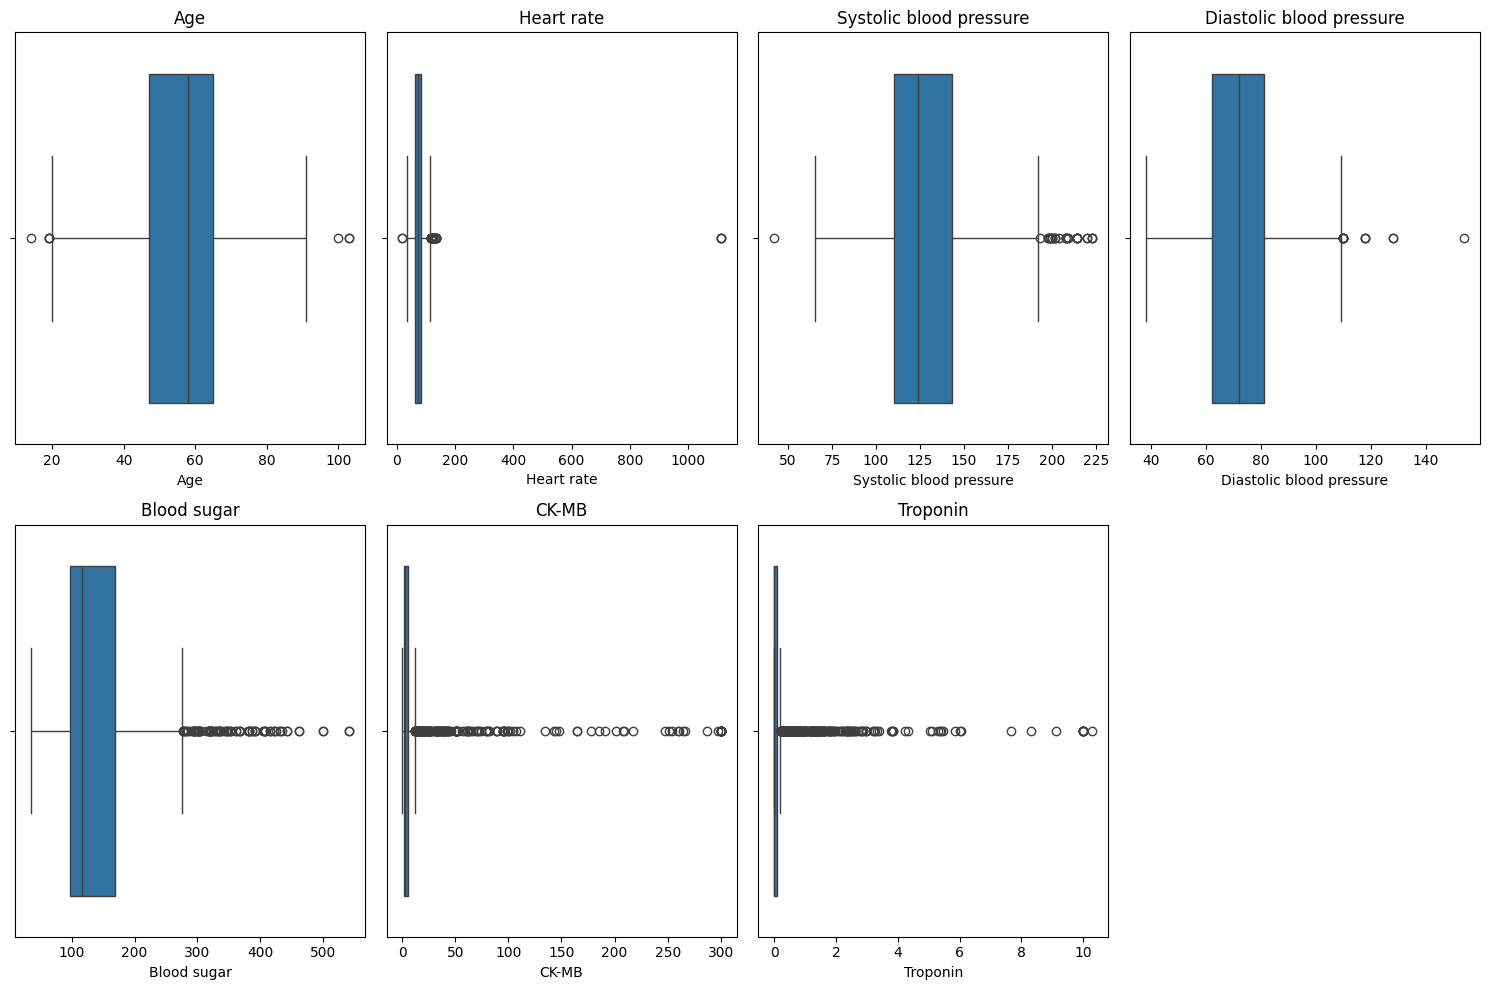

In [8]:
numeric_columns = ['Age', 'Heart rate', 'Systolic blood pressure', 'Diastolic blood pressure', 'Blood sugar', 'CK-MB','Troponin']

plt.figure(figsize=(15, 10))

for idx, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 4, idx)
    sns.boxplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [9]:
Q1 = data[numeric_columns].quantile(0.25)
Q3 = data[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

filter_outliers = ~((data[numeric_columns] < (Q1 - 1.5 * IQR)) |
                    (data[numeric_columns] > (Q3 + 1.5 * IQR))).any(axis=1)

outliers = (~filter_outliers).sum()
outliers

np.int64(530)

Berdasarkan visualisasi yang telah dibuat dapat dilihat bahwa terdapat beberapa feture yang memiliki data outliers dan setelah dihitung jumlah outliers sebanyak 530 baris, ini mencapai 45% dari keseluruhan data sehingga jika ingin direplace denga mean maka tidak bisa menggambarkan informasi keseluruhan data, pada akhirnya data outliers tetap dibiarkan dengan mempertimbangkan beberapa faktor berikut :

* Outliers mencerminkan kondisi klinis ekstrem yang valid.

* Menghapus outliers bisa menghilangkan informasi penting.

* Proporsi outliers terlalu besar, penghapusan bisa bias.

* Model robust seperti tree-based bisa menangani outliers.

* Outliers dapat membantu mendeteksi kasus atau risiko tinggi.

* Outliers mungkin bagian dari variasi biologis alami.

* Penghapusan dapat menurunkan generalisasi model di dunia nyata.

* Fokus pada transformasi atau teknik robust, bukan eliminasi.



### Univariate Analysis

### Categorical

<Axes: ylabel='Result'>

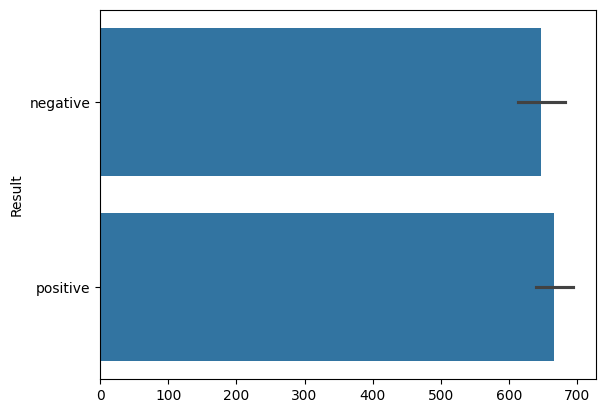

In [10]:
sns.barplot(data['Result'])

Data pada kolom result memiliki jumlah yang hampir seimbang tidak pula terlalu berbeda jauh jadi masih dalam batas aman untuk menjadi traget prediksi model klasifikasi.

### Numerical

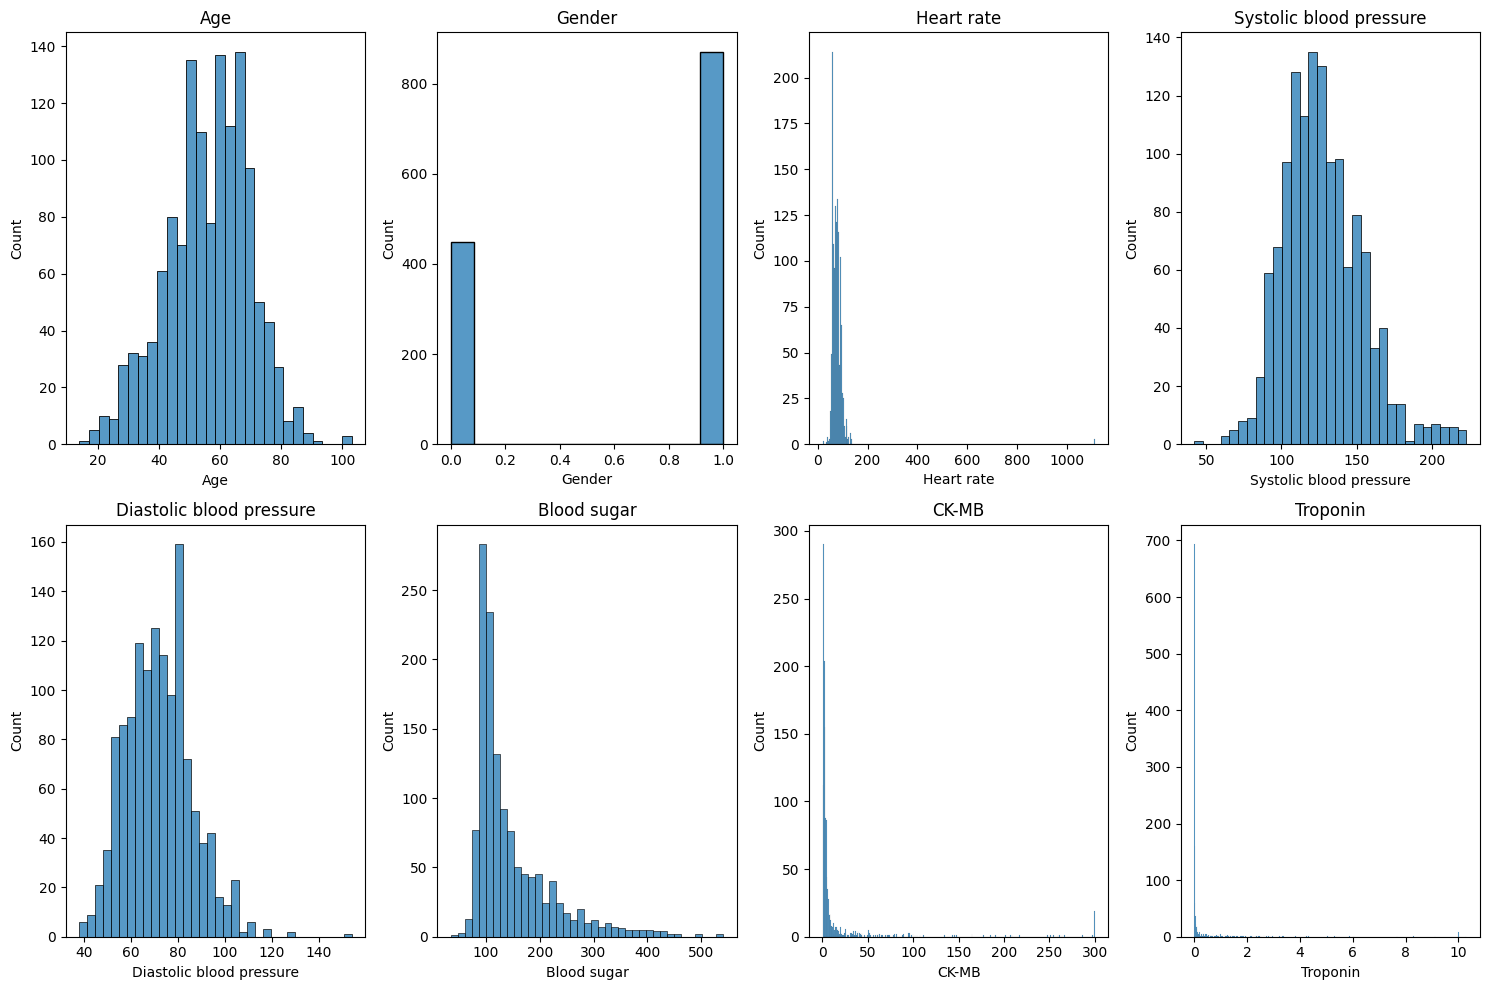

In [11]:
Numeric = data.drop('Result', axis=1)

plt.figure(figsize=(15,10))
for idx, col in enumerate(Numeric, 1):
    plt.subplot(2, 4, idx)
    sns.histplot(x=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

* Age: Distribusi normal, dominan usia 50–70 tahun.

* Gender: Lebih banyak pria (1) dibanding wanita (0).

* Heart Rate: Banyak outlier ekstrem >1000, kemungkinan error.

* Systolic BP: Hampir normal, sebagian tinggi (>200 mmHg).

* Diastolic BP: Skewed kanan, mayoritas 60–90 mmHg.

* Blood Sugar: Skewed kanan, banyak nilai tinggi (>300).

* CK-MB: Skewed kanan ekstrem, indikasi gangguan jantung.

* Troponin: Banyak nilai 0, beberapa ekstrem >10, indikasi klinis serius.

### Multivariate Analysis

#### Categorical

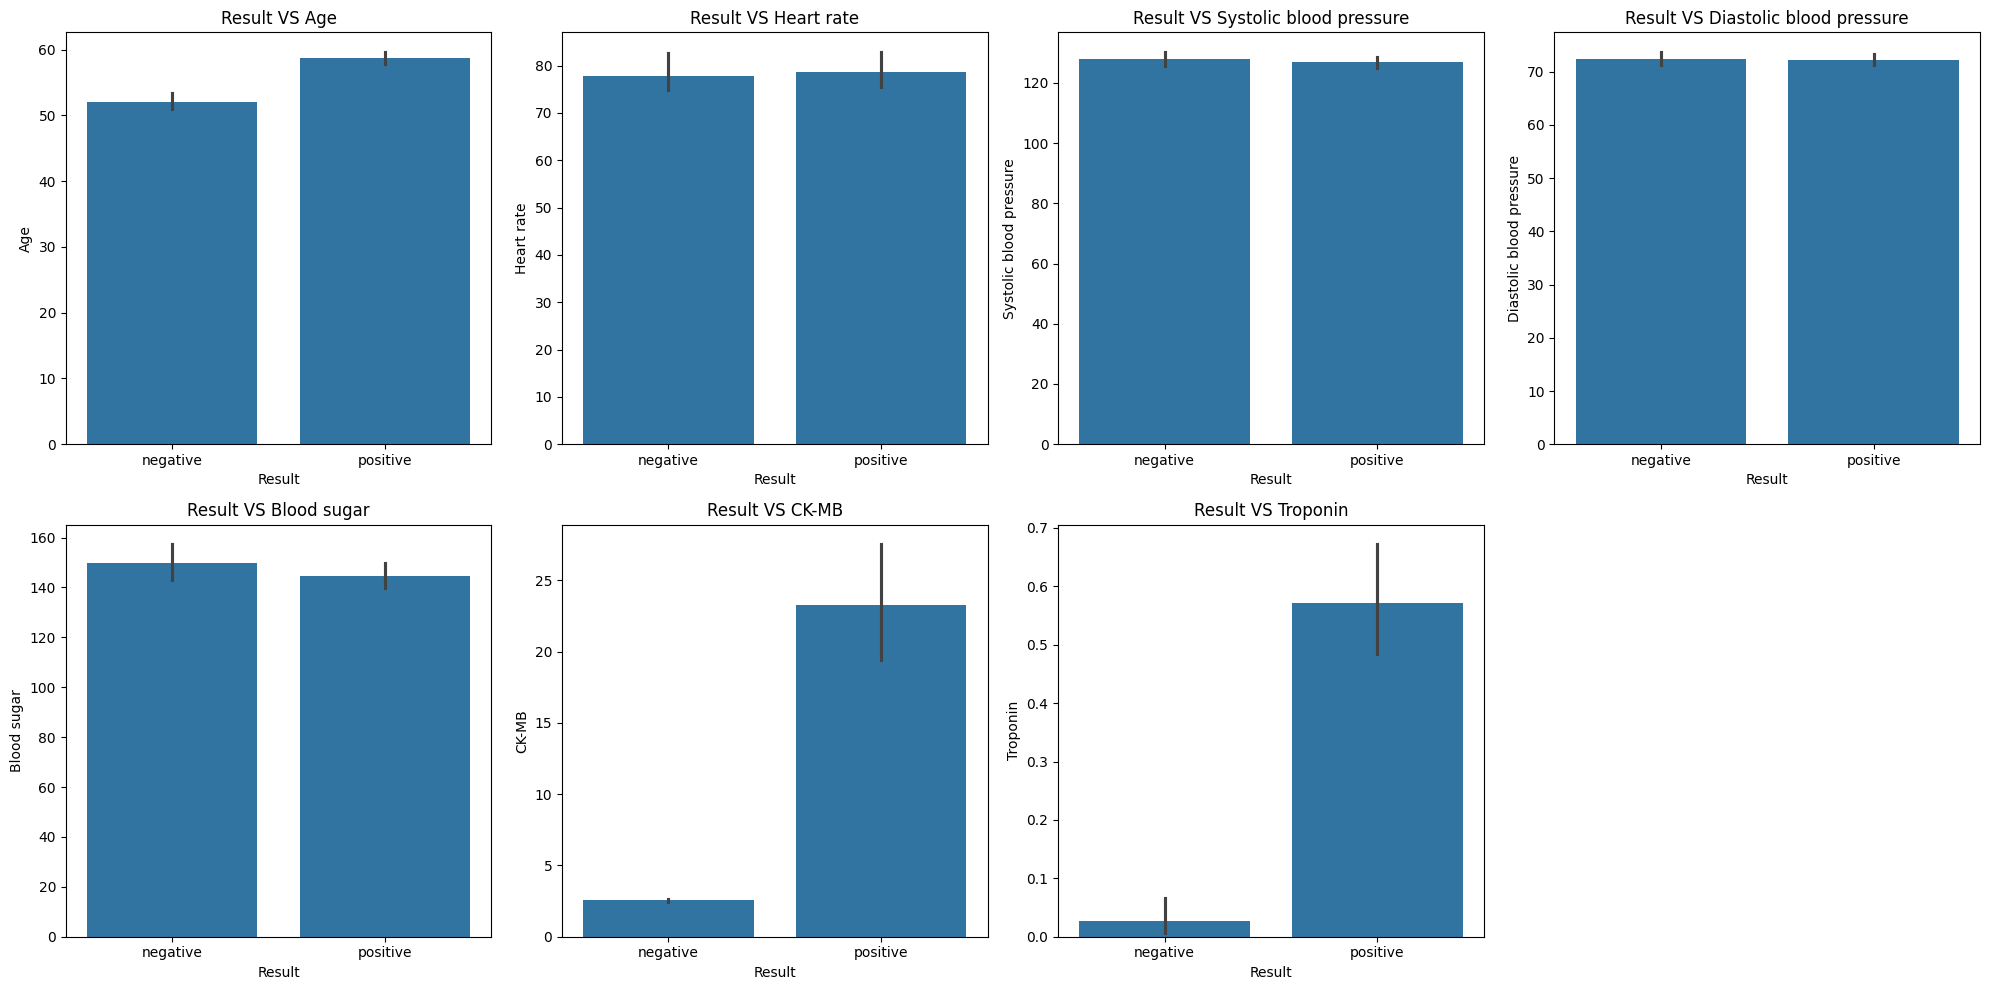

In [12]:
plt.figure(figsize=(20,10))
for idx, col in enumerate(numeric_columns, 1):
    plt.subplot(2, 4, idx)
    sns.barplot(data, x="Result", y=col, estimator='mean')
    plt.title(f'Result VS {col}')

plt.tight_layout()
plt.show()

* Age: Pasien positif cenderung lebih tua dibanding pasien negatif.

* Heart Rate, Systolic & Diastolic BP: Tidak ada perbedaan signifikan antara hasil positif dan negatif.

* Blood Sugar: Sedikit lebih rendah pada pasien positif, namun perbedaannya kecil.

* CK-MB: Rata-rata jauh lebih tinggi pada pasien positif indikasi kuat adanya kerusakan otot jantung.

* Troponin: Jauh lebih tinggi pada pasien positif sangat relevan untuk diagnosis penyakit jantung.

#### Numerical

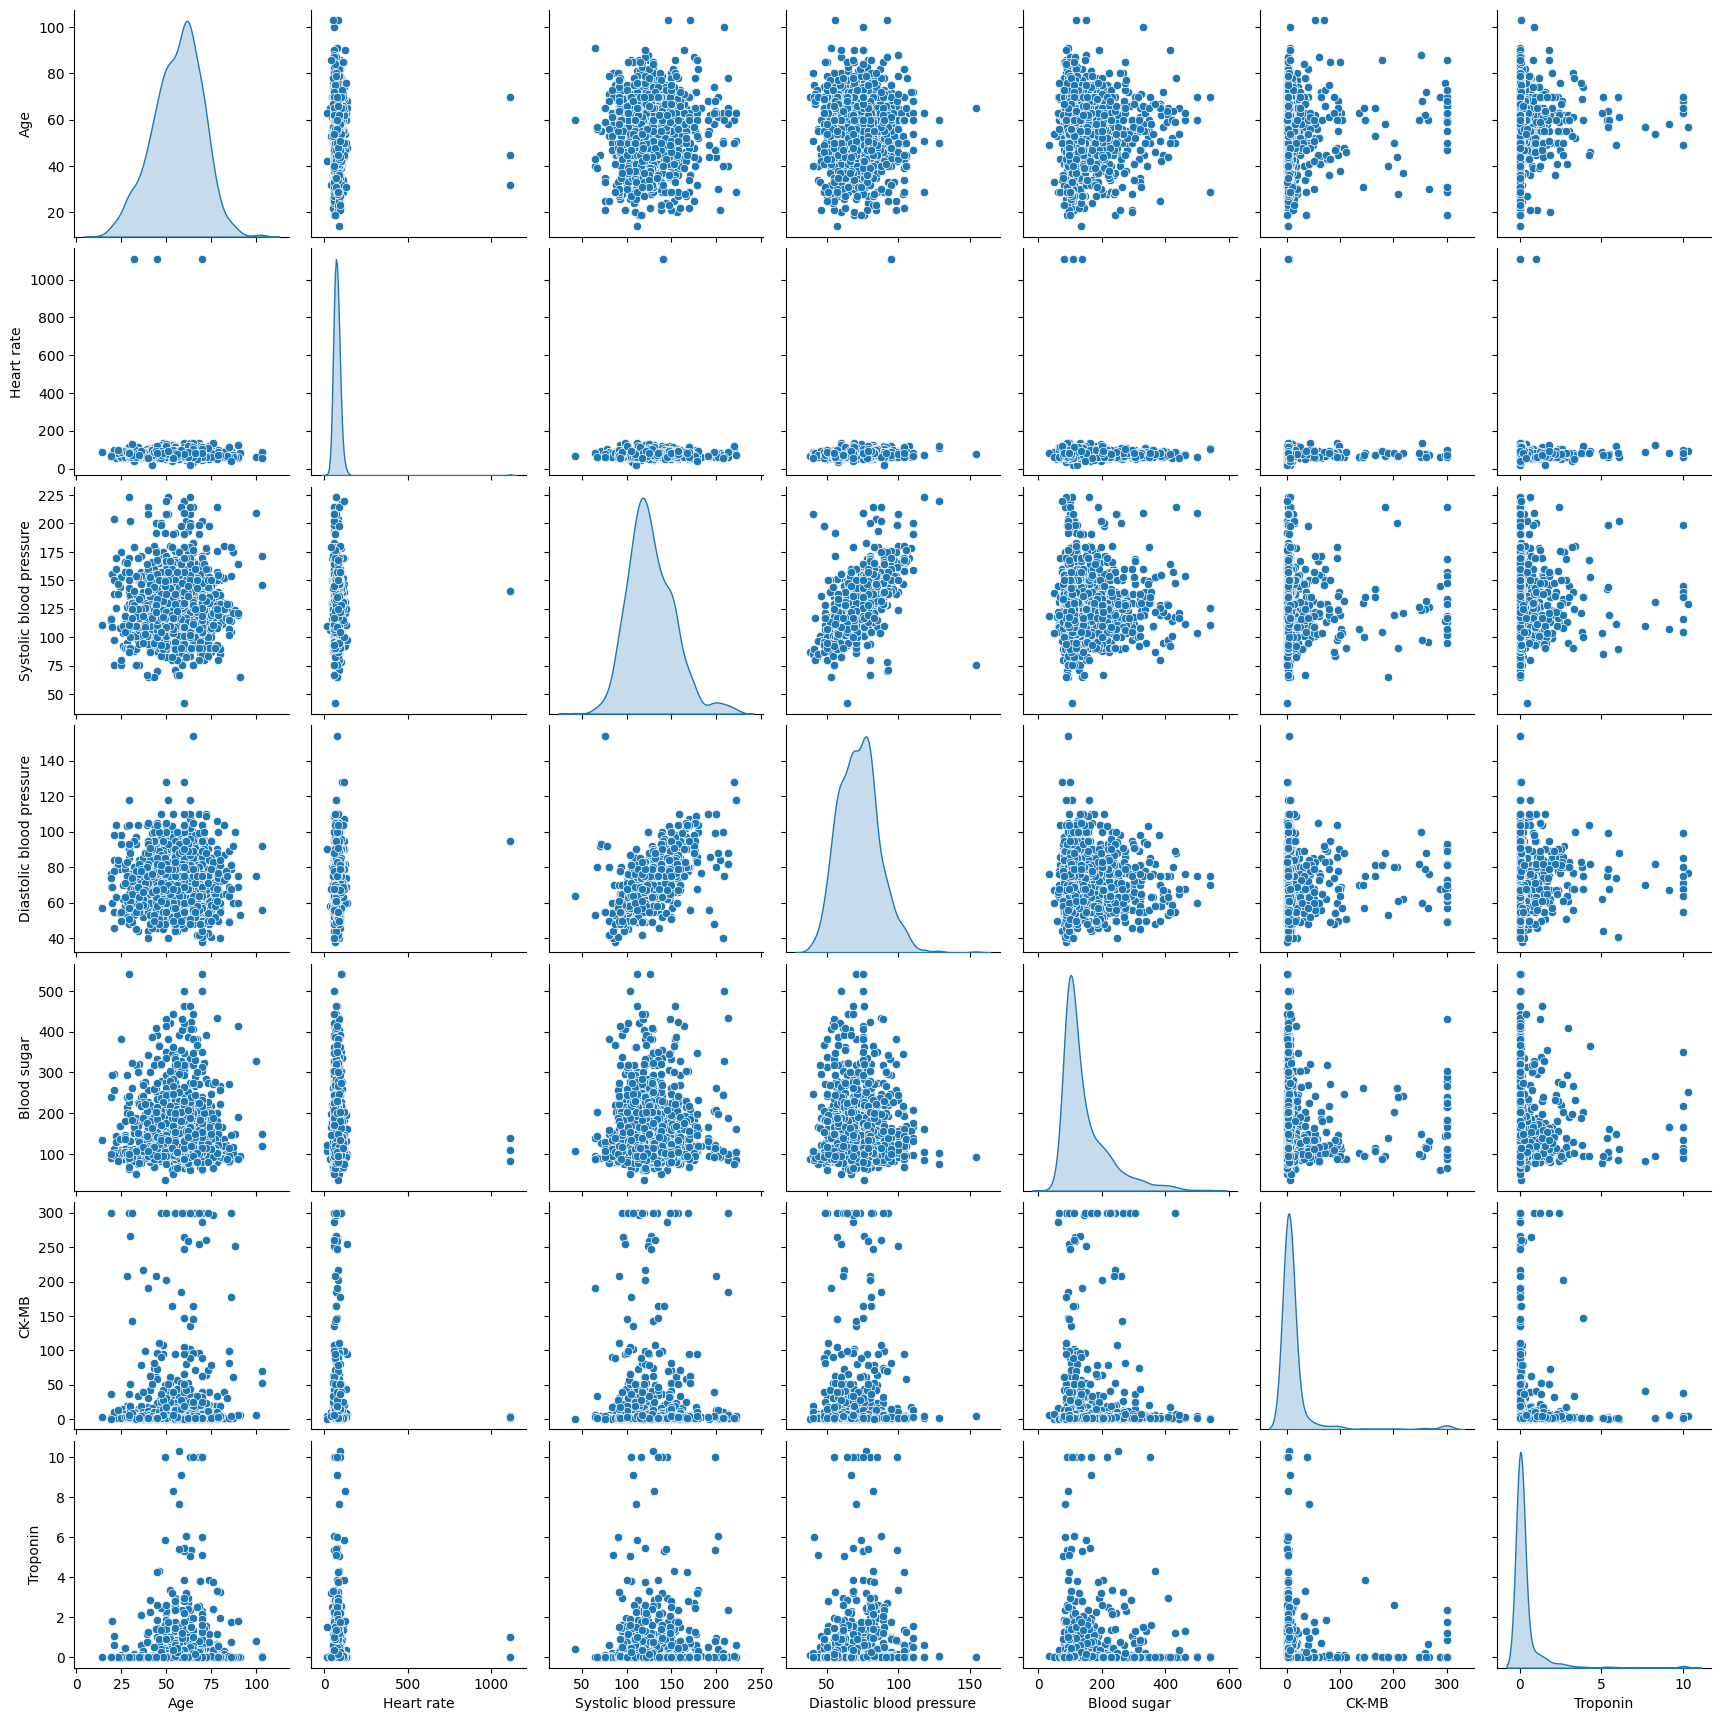

In [13]:
sns.pairplot(data[numeric_columns], diag_kind = 'kde')

* Systolic vs Diastolic Blood Pressure, terlihat korelasi positif yang cukup kuat artinya tekanan darah sistolik dan diastolik cenderung naik bersama
* CK-MB vs Troponin, terlihat korelasi positif, meskipun tidak terlalu kuat artinya peningkatan keduanya bisa sama-sama menjadi indikator masalah jantung.
* CK-MB dan Troponin dengan variabel lain, terlihat tidak menunjukkan hubungan linear yang kuat dengan variabel seperti Age, Heart Rate, Blood Sugar, dll artinya mengindikasikan bahwa keduanya lebih spesifik sebagai penanda klinis.

Text(0.5, 1.0, 'Correlation Matrix untuk Fitur Numerik ')

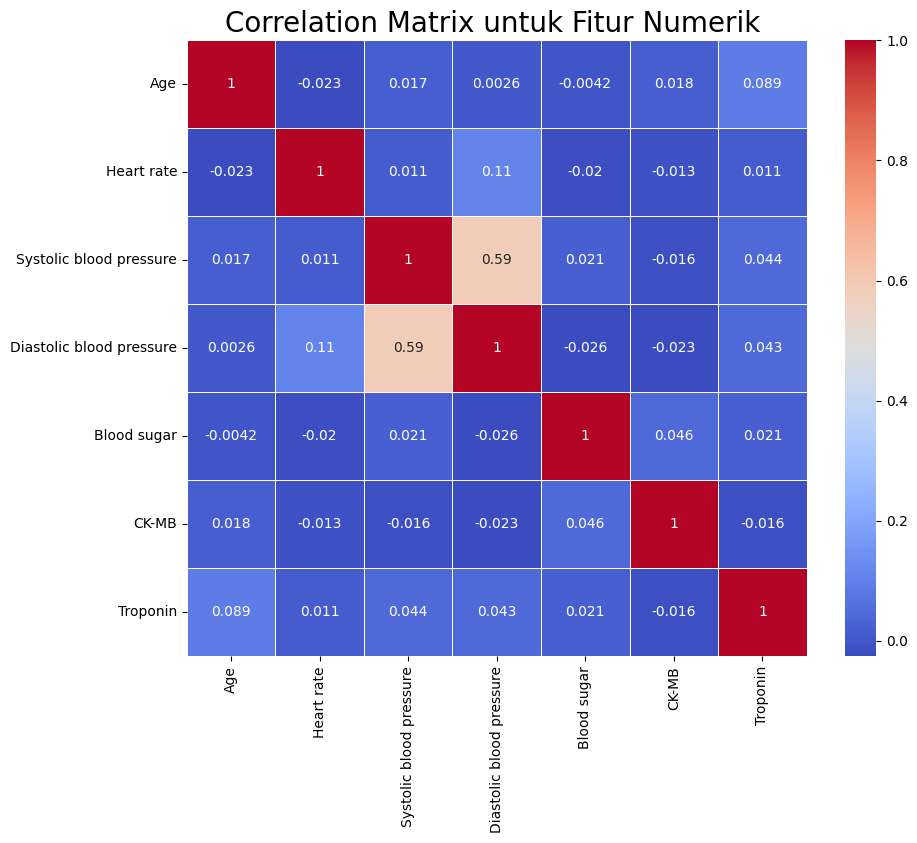

In [14]:
plt.figure(figsize=(10, 8))
correlation_matrix = data[numeric_columns].corr()

sns.heatmap(data=correlation_matrix, annot=True, cmap='coolwarm', linewidths=0.5, )
plt.title("Correlation Matrix untuk Fitur Numerik ", size=20)

* Mayoritas fitur numerik memiliki korelasi yang sangat rendah atau hampir nol satu sama lain.

* Korelasi tertinggi adalah antara Systolic blood pressure dan Diastolic blood pressure dengan nilai 0.59, yang menunjukkan hubungan positif sedang.

* Fitur lain seperti Age, Heart rate, Blood sugar, CK-MB, dan Troponin hampir tidak memiliki korelasi yang signifikan dengan fitur lain.

* Ini menunjukkan bahwa sebagian besar fitur ini bersifat independen secara linear dan bisa diperlakukan sebagai variabel yang berbeda dalam analisis atau pemodelan.

# Data Preparation

## Encoding

In [15]:
encoder = OneHotEncoder(sparse_output=False, feature_name_combiner='concat')
encoded = encoder.fit_transform(data[['Gender']])

encoded = pd.DataFrame(encoded, columns=['Woman', 'Man'])

data = data.drop('Gender', axis=1)

data = pd.concat([data, encoded], axis=1)
data.head()

,Age,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Result,Woman,Man
0,64,66,160,83,160.0,1.80,0.012,negative,0.0,1.0
1,21,94,98,46,296.0,6.75,1.060,positive,0.0,1.0
2,55,64,160,77,270.0,1.99,0.003,negative,0.0,1.0
3,64,70,120,55,270.0,13.87,0.122,positive,0.0,1.0
4,55,64,112,65,300.0,1.08,0.003,negative,0.0,1.0


Melakukan encoding pada kolom Gender karena pada dasarnya gender merupakan tipe data nominal, jadi perlu dilakukan encoding dengan metode one hot encoding untuk membuat 2 kolom baru.

## Membagi data

In [16]:
X = data.drop(["Result"],axis =1)
y = data["Result"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 123)

data dibagi menjadi data train dan test terlebih dahulu, dimana untuk size data pada data test sebesar 30% dari jumlah keseluruhan data sedangkan size untuk data train adalah sisanya yaitu 70% data keseluruhan.

### Standarisasi

In [17]:
columns = X.columns

scaler = StandardScaler()
scaler.fit(X_train)

X_train = scaler.transform(X_train)
X_train = pd.DataFrame(X_train, columns=columns)
X_train.head()

,Age,Heart rate,Systolic blood pressure,Diastolic blood pressure,Blood sugar,CK-MB,Troponin,Woman,Man
0,-0.601608,-0.127283,0.915568,1.696168,-0.637030,-0.001813,-0.297891,-0.724996,0.724996
1,-1.990184,0.190344,1.109738,0.969216,-0.544983,-0.210637,-0.306766,-0.724996,0.724996
2,1.225465,-0.325801,-0.637797,-0.193906,1.032964,-0.308361,-0.296278,1.379317,-1.379317
3,-0.893940,0.249900,-1.026138,-0.048516,-0.426637,-0.176400,-0.297891,1.379317,-1.379317
4,-1.478603,-0.385356,0.410724,0.678436,-0.650179,-0.241473,-0.306766,1.379317,-1.379317


Standarisasi dilakukan untuk menyamakan skala nilai pada datasets sebelumnya kita perhatikan bahwa setiap kolom/ feature memiliki skala nilai yang berbeda-beda dengan scaling maka skala semua nilai antar feature dapat sama.

# Model Development

## Tabel perbandingan

In [18]:
models = pd.DataFrame(index=['train_acc', 'test_acc'],
                      columns=['DecisionTree', 'RandomForest', 'GradientBoosting', 'KNN', 'LogisticRegression'])

Sebeleum melakukan modeling dibuat tabel untuk menampung hasil akurasi tests dan train dari masing-masing algoritma.

### Decision Tree

In [19]:
DC = DecisionTreeClassifier(
    random_state=123,
    criterion='gini',
    max_depth=25,
    min_samples_split=8,
    min_samples_leaf=5,
    max_features='sqrt',
)

In [20]:
DC.fit(X_train, y_train)
models.loc['train_acc','DecisionTree'] = accuracy_score(y_train, DC.predict(X_train))
models.loc['test_acc', 'DecisionTree'] = accuracy_score(y_test, DC.predict(X_test))

### Random Forest

In [21]:
RF = RandomForestClassifier(
    random_state=123,
    criterion='gini',
    max_depth=25,
    min_samples_split=8,
    min_samples_leaf=5,
    max_features='sqrt')

In [22]:
RF.fit(X_train, y_train)
models.loc['train_acc','RandomForest'] = accuracy_score(y_train, RF.predict(X_train))
models.loc['test_acc', 'RandomForest'] = accuracy_score(y_test, RF.predict(X_test))

### Gradient Booster

In [23]:
GB = GradientBoostingClassifier(
    random_state=123,
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=3,
)

In [24]:
GB.fit(X_train, y_train)
models.loc['train_acc','GradientBoosting'] = accuracy_score(y_train, GB.predict(X_train))
models.loc['test_acc', 'GradientBoosting'] = accuracy_score(y_test, GB.predict(X_test))

## KNN

In [25]:
KNN = KNeighborsClassifier(
    n_neighbors=5,
    metric='manhattan',
    weights='distance',
    algorithm='auto',
    leaf_size=30,
)

In [26]:
KNN.fit(X_train, y_train)
models.loc['train_acc','KNN'] = accuracy_score(y_train, KNN.predict(X_train))
models.loc['test_acc', 'KNN'] = accuracy_score(y_test, KNN.predict(X_test))

## Logistic Regression

In [27]:
LR = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    C=0.01,
    l1_ratio=0.01
    )

In [28]:
LR.fit(X_train, y_train)
models.loc['train_acc','LogisticRegression'] = accuracy_score(y_train, LR.predict(X_train))
models.loc['test_acc', 'LogisticRegression'] = accuracy_score(y_test, LR.predict(X_test))

# Evaluasi Model

In [29]:
models

,DecisionTree,RandomForest,GradientBoosting,KNN,LogisticRegression
train_acc,0.971831,0.989166,1.0,1.0,0.67714
test_acc,0.631313,0.631313,0.631313,0.631313,0.651515


* Overfitting pada DecisionTree, RandomForest, GradientBoosting, dan KNN memiliki akurasi pelatihan sangat tinggi (≥97%) tetapi akurasi pengujian rendah (≈63%). Hal ini menunjukkan bahwa model terlalu “menghafal” data latih dan gagal menggeneralisasi ke data baru (overfitting).

* Logistic Regression lebih stabil dimana akurasi pelatihan dan pengujian lebih seimbang (train: 67.7%, test: 65.2%), menunjukkan bahwa model ini tidak overfit seperti model lainnya. Meskipun akurasinya tidak tertinggi, Logistic Regression lebih general dan cocok untuk baseline.